# CECS 385 — Find the best 3 ETFs out of 100

**Goal:** Compare an exact classical search against a simple greedy heuristic using the **same** predicted returns and covariance data. Exactly 3 ETFs are chosen with equal weights (1/3 each). There are **161,700** possible combinations.

The notebook uses **demo data by default**. Choose `CSV` for your own actual 100-ETF adjusted-price data. It uses a pooled Random Forest to predict **January 2025** returns from information known by **December 2024**. Neither January 2025 returns nor future periods enter the training data.

**Important:** This is a classical 100-ETF benchmark. It does **not** perform 100-qubit QAOA: normal Colab resources cannot realistically simulate dense 100-qubit QAOA. Don't present these results as a quantum comparison.

In [4]:
# In Colab, uncomment if needed:
!pip install -q numpy pandas scikit-learn matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


In [5]:
import itertools
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

DATA_MODE = "DEMO"       # Change to "CSV" for your historical ETF prices
CSV_PATH = "/content/etf_prices.csv"
PICK = 3
RISK_LAMBDA = 1.0
SEED = 42
FORECAST_DATE = "2024-12-31"   # Predict January 2025
TEST_DATE = "2025-01-31"

## 1. Load prices

For `CSV` mode, upload a CSV to Colab. It should have a `Date` column and **at least 100 ETF ticker columns** containing **adjusted closing prices**. The notebook requires 100 ETFs with complete monthly observations in the period used. Using adjusted prices prevents splits and distributions from distorting returns.

`DEMO` makes **fake ETF-like prices**, so its results cannot support a claim about market history.

In [6]:
if DATA_MODE == "DEMO":
    rng = np.random.default_rng(SEED)
    dates = pd.date_range("2015-01-31", "2025-01-31", freq="ME")
    market = rng.normal(0.006, 0.04, len(dates))
    group = rng.normal(0, 0.025, (len(dates), 10))
    all_returns = {}
    for i in range(100):
        monthly_change = (rng.normal(0.004, 0.008) +
                          rng.uniform(0.5, 1.2) * market +
                          group[:, i % 10] + rng.normal(0, 0.018, len(dates)))
        all_returns[f"ETF{i+1:03d}"] = monthly_change
    monthly = pd.DataFrame(all_returns, index=dates)
    prices = 100 * (1 + monthly).cumprod()
elif DATA_MODE == "CSV":
    prices = pd.read_csv(CSV_PATH)
    prices["Date"] = pd.to_datetime(prices["Date"])
    prices = prices.set_index("Date").sort_index()
    prices = prices.apply(pd.to_numeric, errors="coerce")
    prices = prices.resample("ME").last()
else:
    raise ValueError('DATA_MODE must be "DEMO" or "CSV"')

prices = prices.loc["2015-01-31":"2025-01-31"]
prices = prices.loc[:, prices.notna().all() & (prices > 0).all()]
if len(prices.columns) < 100:
    raise ValueError(f"Only {len(prices.columns)} ETF columns have complete prices; need 100.")
prices = prices.iloc[:, :100].copy()
monthly = prices.pct_change().dropna()

if pd.Timestamp(FORECAST_DATE) not in monthly.index or pd.Timestamp(TEST_DATE) not in monthly.index:
    raise ValueError("Need both December 2024 and January 2025 in monthly prices.")

print("Mode:", DATA_MODE)
print("ETFs:", len(prices.columns))
print("First 10:", list(prices.columns[:10]))
print("Months:", len(monthly))
prices.iloc[:, :5].tail()

Mode: DEMO
ETFs: 100
First 10: ['ETF001', 'ETF002', 'ETF003', 'ETF004', 'ETF005', 'ETF006', 'ETF007', 'ETF008', 'ETF009', 'ETF010']
Months: 120


,ETF001,ETF002,ETF003,ETF004,ETF005
2024-09-30,106.026749,633.212835,365.669749,31.922409,254.606349
2024-10-31,104.601869,640.904431,350.617641,32.036564,258.587273
2024-11-30,108.155343,686.572510,405.880046,32.697228,254.392532
2024-12-31,109.179015,667.865737,400.512681,33.331410,265.676647
2025-01-31,101.932716,656.270464,374.495578,32.926475,255.860504


## 2. Random Forest predicts returns

One pooled Random Forest learns from **lagged** market features through December 2024 (the latest labeled target is December). The forecast uses features observed at the end of December 2024 to predict January 2025. Monthly predictions are converted to annual return estimates by multiplying by 12. This is a classroom baseline rather than a validated forecasting system.

In [7]:
# Each row describes ETF behavior at month t, and the target is month t+1.
rows = []
for ticker in monthly.columns:
    r = monthly[ticker]
    for i in range(6, len(monthly) - 1):
        month = monthly.index[i]
        rows.append({
            "date": month,
            "ticker": ticker,
            "r1": r.iloc[i],
            "r3": (1 + r.iloc[i-2:i+1]).prod() - 1,
            "r6": (1 + r.iloc[i-5:i+1]).prod() - 1,
            "vol6": r.iloc[i-5:i+1].std(),
            "next_return": r.iloc[i+1]
        })
features = pd.DataFrame(rows)
feature_names = ["r1", "r3", "r6", "vol6"]

# Training rows must have a target month no later than Dec 2024.
train = features[features["date"] < pd.Timestamp(FORECAST_DATE)]
model = RandomForestRegressor(n_estimators=80, min_samples_leaf=5,
                              random_state=SEED, n_jobs=-1)
model.fit(train[feature_names], train["next_return"])

# Forecast January using December's known price history.
forecast_rows = []
for ticker in monthly.columns:
    r = monthly.loc[:FORECAST_DATE, ticker]
    forecast_rows.append({
        "ticker": ticker,
        "r1": r.iloc[-1],
        "r3": (1+r.iloc[-3:]).prod()-1,
        "r6": (1+r.iloc[-6:]).prod()-1,
        "vol6": r.iloc[-6:].std()
    })
forecast = pd.DataFrame(forecast_rows)
forecast["predicted_monthly"] = model.predict(forecast[feature_names])
forecast["predicted_annual"] = forecast["predicted_monthly"] * 12
print("Training rows:", len(train))
print(forecast[["ticker", "predicted_monthly"]].head())

Training rows: 11200
   ticker  predicted_monthly
0  ETF001           0.020062
1  ETF002           0.012035
2  ETF003           0.004485
3  ETF004           0.008036
4  ETF005           0.012446


## 3. Same objective for both algorithms

Score = predicted annual return − `RISK_LAMBDA` × predicted annual **portfolio variance**.

For three equal-weight funds, all weights equal 1/3. The covariance matrix is estimated from the 36 months before January 2025. This is a fixed **in-sample optimization score**, not a guaranteed future return.

In [8]:
tickers = forecast["ticker"].tolist()
mu = forecast["predicted_annual"].to_numpy()
cov = monthly.loc[:FORECAST_DATE, tickers].tail(36).cov().to_numpy() * 12

def score(ids):
    ids = np.array(ids, dtype=int)
    expected_return = mu[ids].sum() / PICK
    portfolio_variance = cov[np.ix_(ids, ids)].sum() / (PICK ** 2)
    return float(expected_return - RISK_LAMBDA * portfolio_variance)

# Exact exhaustive search: all 100 choose 3 = 161,700 portfolios
start = time.perf_counter()
combos = np.array(list(itertools.combinations(range(100), PICK)), dtype=int)
expected = mu[combos].sum(axis=1) / PICK
risk = np.zeros(len(combos))
for a in range(PICK):
    for b in range(PICK):
        risk += cov[combos[:, a], combos[:, b]]
risk = risk / PICK**2
scores = expected - RISK_LAMBDA * risk
best_pos = int(np.argmax(scores))
exact_ids = combos[best_pos].tolist()
exact_score = float(scores[best_pos])
exact_seconds = time.perf_counter() - start

# Greedy: choose one ETF at a time based on the provisional score.
start = time.perf_counter()
greedy_ids = []
for step in range(PICK):
    choices = [i for i in range(100) if i not in greedy_ids]
    best_next = max(choices, key=lambda i: score(greedy_ids + [i]))
    greedy_ids.append(best_next)
greedy_score = score(greedy_ids)
greedy_seconds = time.perf_counter() - start

print("Total possible portfolios:", len(combos))
print("Exact portfolio:", [tickers[i] for i in exact_ids])
print("Greedy portfolio:", [tickers[i] for i in greedy_ids])
print("Score gap:", exact_score - greedy_score)

Total possible portfolios: 161700
Exact portfolio: ['ETF008', 'ETF044', 'ETF087']
Greedy portfolio: ['ETF044', 'ETF008', 'ETF087']
Score gap: 0.0


## 4. Compare the best portfolios

January 2025 is held out and only used to evaluate the two selected portfolios. A single month is **not** enough to compare Sharpe ratios or make a scientific claim of superior investment performance.

         Method          Selected ETFs  Objective score  Gap from exact  Runtime (sec)  Jan 2025 return
Classical exact ETF008, ETF044, ETF087         0.305176             0.0        0.09722        -0.048698
         Greedy ETF044, ETF008, ETF087         0.305176             0.0        0.00306        -0.048698


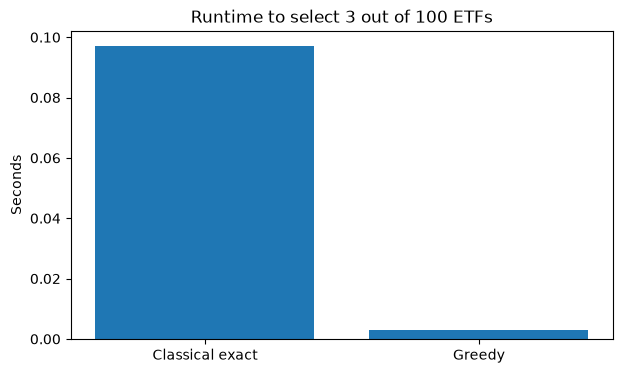

In [9]:
jan = monthly.loc[TEST_DATE, tickers]
results = []
for method, ids, s, secs in [
    ("Classical exact", exact_ids, exact_score, exact_seconds),
    ("Greedy", greedy_ids, greedy_score, greedy_seconds)
]:
    chosen = [tickers[i] for i in ids]
    results.append({
        "Method": method,
        "Selected ETFs": ", ".join(chosen),
        "Objective score": round(s, 6),
        "Gap from exact": round(exact_score - s, 6),
        "Runtime (sec)": round(secs, 5),
        "Jan 2025 return": round(float(jan[chosen].mean()), 6)
    })
results = pd.DataFrame(results)
print(results.to_string(index=False))
results.to_csv("three_out_of_100_results.csv", index=False)

plt.figure(figsize=(7, 4))
plt.bar(results["Method"], results["Runtime (sec)"])
plt.title("Runtime to select 3 out of 100 ETFs")
plt.ylabel("Seconds")
plt.show()

## What the results mean

- The **exact** method is the best by the *defined objective*; its score gap is zero by construction.
- **Greedy** is faster but may or may not find the same portfolio.
- January 2025 actual returns are held out. A different return does **not** prove one optimizer is intrinsically better.
- These are **not quantum results**. Full dense 100-qubit QAOA is impractical to simulate in a normal Colab session. To compare quantum and classical fairly, run genuine QAOA on a smaller common subset and use the same input estimates, score, and rules.
- To test your professor's hypotheses, repeat over independent random seeds (for QAOA) and multiple historical decision months. Report optimality rates, gaps, runtimes, and uncertainty.